In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from probly.evaluation.active_learning import (
    from_dataset,
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    compute_accuracy,
    compute_nauc
)

| Funktion / Klasse | Aufgabe |
|---|---|
| `make_moons` | Erzeugt unseren binären Datensatz |
| `train_test_split` | Teilt die Daten in Trainings- und Testdaten |
| `RandomForestClassifier` | Unser erstes Klassifikationsmodell |
| `from_dataset` | Erstellt den Active-Learning-Datenpool |
| `MarginSampling` | Wählt besonders unsichere Datenpunkte |
| `RandomQuery` | Wählt zufällige Datenpunkte |
| `active_learning_steps` | Führt die Active-Learning-Schritte aus |
| `compute_accuracy` | Berechnet die Genauigkeit |
| `compute_nauc` | Bewertet die Entwicklung der Genauigkeit über mehrere Schritte |

Datensatz erstellen

In [ ]:
X, y = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42 #sorgt dafür, dass zufallsabhängige Schritte reproduzierbar sind.
)

Daten visualisieren

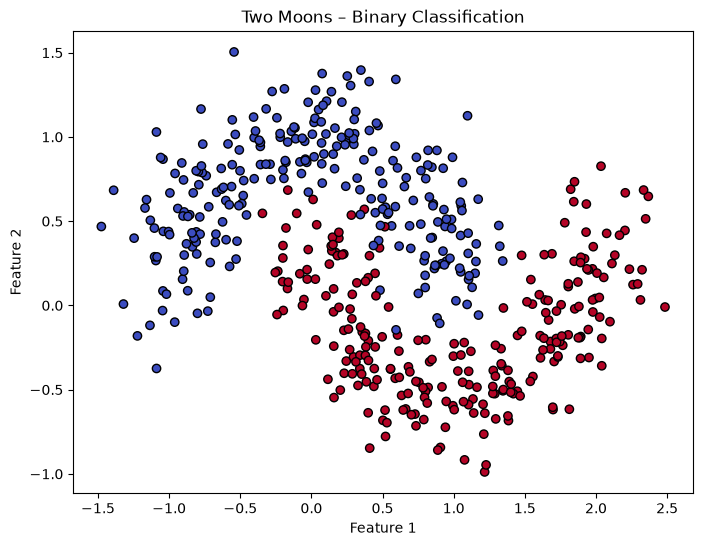

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolor="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two Moons – Binary Classification")
plt.show()

Trainings- und Testdaten aufteilen

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Trainingsdaten:", X_train.shape)
print("Testdaten:", X_test.shape)

Trainingsdaten: (400, 2)
Testdaten: (100, 2)


Random-Forest-Modell erstellen

In [12]:
estimator = RandomForestClassifier(
    n_estimators=100, #Der Random Forest besteht aus 100 Entscheidungsbäumen.
    random_state=42 #Macht die zufallsabhängigen Schritte reproduzierbar.
) 
#hier wurde das Modell noch nicht trainiert, wir erstellen nur das Modellobjekt. 
# Das Training erfolgt später im Active Learning Prozess.

Active-Learning-Pool mit Probly erstellen

In [ ]:
pool = from_dataset(
    X_train,
    y_train,
    X_test,
    y_test,
    initial_size=30,
    seed=42
)

In [7]:
print("Gelabelte Daten:", pool.n_labeled)
print("Ungelabelte Daten:", pool.n_unlabeled)

Gelabelte Daten: 20
Ungelabelte Daten: 380


In [8]:
import inspect

strategy = MarginSampling()

print("Methode:", inspect.signature(strategy.select))
print("\nImplementierung:")
print(inspect.getsource(strategy.select))

Methode: (estimator: 'Estimator', pool: 'ActiveLearningPool', n: 'int') -> 'ArrayLike'

Implementierung:
    def select(self, estimator: Estimator, pool: ActiveLearningPool, n: int) -> ArrayLike:
        """Return n indices with the smallest margin in predicted probabilities."""
        n = min(n, pool.n_unlabeled)
        scores = margin_score(estimator.predict_proba(pool.x_unlabeled))
        return topk_select(scores, n)



Wir bauen zuerst K-Means als eigenständige Probly-Query-Strategie. Danach können wir dieselbe Schnittstelle für E-Means verwenden.

So können wir später beide Verfahren problemlos mit Margin Sampling kombinieren und unsere JSD- bzw. epistemisch gesteuerten Wechselstrategien entwickeln.

K-Means als Query-Strategie implementieren

In [9]:
from sklearn.cluster import KMeans

Unsere eigene Query-Strategie erstellen

In [10]:
class KMeansQuery:

    def __init__(self, random_state=42):
        self.random_state = random_state

    def select(self, estimator, pool, n):

        X_unlabeled = pool.x_unlabeled #ungelabelte Datenpunkte holen

        kmeans = KMeans( #kMeans-Algorithmus ausführen, um die ungelabelten Datenpunkte in n Cluster zu gruppieren (hier 10 Cluster)
            n_clusters=n,
            random_state=self.random_state,
            n_init=10
        )

        cluster_labels = kmeans.fit_predict(X_unlabeled) #Clusterzugehörigkeit jedes ungelabelten Datenpunkts bestimmen

        selected_indices = []

        for cluster in range(n):

            cluster_indices = np.where(
                cluster_labels == cluster
            )[0]

            cluster_points = X_unlabeled[cluster_indices]

            center = kmeans.cluster_centers_[cluster] #repräsentativer Punkt (Clusterzentrum) auswählen

            distances = np.linalg.norm(
                cluster_points - center,
                axis=1
            )

            closest_index = cluster_indices[np.argmin(distances)]

            selected_indices.append(closest_index)

        return np.array(selected_indices) #indizes der ausgewählten Punkte zurückgeben

Strategie testen

In [13]:
kmeans_query = KMeansQuery()

selected_indices = kmeans_query.select(
    estimator,
    pool,
    n=10
)

print("Ausgewählte Indizes:", selected_indices)
print("Anzahl ausgewählter Datenpunkte:", len(selected_indices))

Ausgewählte Indizes: [ 98 299 158 204  35  59   1  78 315 271]
Anzahl ausgewählter Datenpunkte: 10


select()-Methode ist so aufgebaut, dass sie dieselbe Schnittstelle wie Problys vorhandene Query-Strategien verwendet

K-Means mit Probly verbinden
Wir verwenden dafür active_learning_steps(). Diese Funktion übernimmt den Active-Learning-Ablauf:
1. Random Forest wird mit den 20 gelabelten Datenpunkten trainiert.
2. Unsere K-Means-Strategie wählt 10 Datenpunkte aus.
3. Probly fügt deren Labels zum Trainingsdatensatz hinzu.
4. Random Forest wird erneut trainiert.
5. Der Vorgang wird wiederholt.
Die Funktion ist genau für diesen Ablauf vorgesehen.

In [ ]:
results_kmeans = []

for state in active_learning_steps(
    pool, #aktiv-learning-Pool
    estimator, #das Modell, das trainiert werden soll(RF)
    KMeansQuery(), #Query-Strategie (KMeans)
    query_size=20, #pro Iteration werden 20 Datenpunkte ausgewählt
    n_iterations=10 #wir füheren maximal 10 Auswahl- und Trainingsschritte durch
):
    predictions = state.estimator.predict(state.pool.x_test)

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_kmeans.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration:2d} | "
        f"Gelabelte Daten: {state.pool.n_labeled:3d} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration:  0 | Gelabelte Daten:  20 | Accuracy: 0.760
Iteration:  1 | Gelabelte Daten:  30 | Accuracy: 0.880
Iteration:  2 | Gelabelte Daten:  40 | Accuracy: 0.880
Iteration:  3 | Gelabelte Daten:  50 | Accuracy: 0.920
Iteration:  4 | Gelabelte Daten:  60 | Accuracy: 0.920
Iteration:  5 | Gelabelte Daten:  70 | Accuracy: 0.920
Iteration:  6 | Gelabelte Daten:  80 | Accuracy: 0.920
Iteration:  7 | Gelabelte Daten:  90 | Accuracy: 0.930
Iteration:  8 | Gelabelte Daten: 100 | Accuracy: 0.940
Iteration:  9 | Gelabelte Daten: 110 | Accuracy: 0.930
Iteration: 10 | Gelabelte Daten: 120 | Accuracy: 0.930


Margin Sampling implementieren und testen
Einen neuen Active-Learning-Pool erstellen: Für einen fairen Vergleich sollen beide Strategien mit denselben Ausgangsbedingungen starten.

In [ ]:
pool_margin = from_dataset(
    X_train,
    y_train,
    X_test,
    y_test,
    initial_size=30,
    seed=42
)

Margin Sampling ausführen

In [16]:
estimator_margin = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [ ]:
results_margin = []

for state in active_learning_steps(
    pool_margin,
    estimator_margin,
    MarginSampling(),
    query_size=20,
    n_iterations=10
):
    predictions = state.estimator.predict(state.pool.x_test)

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_margin.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration:2d} | "
        f"Gelabelte Daten: {state.pool.n_labeled:3d} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration:  0 | Gelabelte Daten:  20 | Accuracy: 0.760
Iteration:  1 | Gelabelte Daten:  30 | Accuracy: 0.890
Iteration:  2 | Gelabelte Daten:  40 | Accuracy: 0.970
Iteration:  3 | Gelabelte Daten:  50 | Accuracy: 0.970
Iteration:  4 | Gelabelte Daten:  60 | Accuracy: 0.950
Iteration:  5 | Gelabelte Daten:  70 | Accuracy: 0.970
Iteration:  6 | Gelabelte Daten:  80 | Accuracy: 0.940
Iteration:  7 | Gelabelte Daten:  90 | Accuracy: 0.970
Iteration:  8 | Gelabelte Daten: 100 | Accuracy: 0.950
Iteration:  9 | Gelabelte Daten: 110 | Accuracy: 0.950
Iteration: 10 | Gelabelte Daten: 120 | Accuracy: 0.950


K-Means und Margin Sampling vergleichen

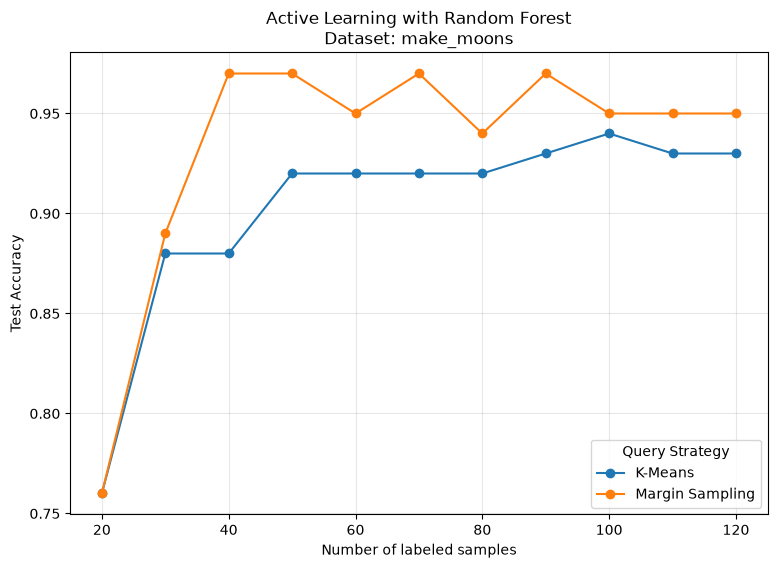

In [21]:
plt.figure(figsize=(9, 6))

plt.plot(
    x_kmeans,
    y_kmeans,
    marker="o",
    label="K-Means"
)

plt.plot(
    x_margin,
    y_margin,
    marker="o",
    label="Margin Sampling"
)

plt.xlabel("Number of labeled samples")
plt.ylabel("Test Accuracy")

plt.title(
    "Active Learning with Random Forest\n"
    "Dataset: make_moons"
)

plt.legend(title="Query Strategy")
plt.grid(alpha=0.3)
plt.show()

AUBC und NAUC berechnen

In [20]:
# K-Means
x_kmeans = np.array([
    r["labeled_samples"] for r in results_kmeans
])

y_kmeans = np.array([
    r["accuracy"] for r in results_kmeans
])

aubc_kmeans = np.trapezoid(y_kmeans, x_kmeans)


# Margin Sampling
x_margin = np.array([
    r["labeled_samples"] for r in results_margin
])

y_margin = np.array([
    r["accuracy"] for r in results_margin
])

aubc_margin = np.trapezoid(y_margin, x_margin)


print("Learner: Random Forest")
print("AUBC K-Means:", round(aubc_kmeans, 3))
print("AUBC Margin Sampling:", round(aubc_margin, 3))

Learner: Random Forest
AUBC K-Means: 90.85
AUBC Margin Sampling: 94.15


E-Means implementieren
Implementierung enthält:
1. Initialisierung der Cluster-Mittelpunkte.
2. Aufteilung der Daten in Mini-Batches.
3. Zuordnung der Datenpunkte zu den nächsten Mittelpunkten.
4. Aktualisierung der Mittelpunkte mithilfe von EMA.
5. Cosine Schedule zur schrittweisen Verringerung der Aktualisierungsstärke.
6. Finalisierung der Cluster-Mittelpunkte.

E-Means als eigene Klasse programmieren

In [22]:
class EMeansQuery:

    def __init__(
        self,
        random_state=42,
        epochs=5,
        batch_size=64,
        alpha0=0.5
    ):
        self.random_state = random_state
        self.epochs = epochs
        self.batch_size = batch_size
        self.alpha0 = alpha0

    def select(self, estimator, pool, n):

        X = np.asarray(pool.x_unlabeled, dtype=float)

        rng = np.random.default_rng(self.random_state)

        # 1. Initialisierung der Cluster-Mittelpunkte
        centers = X[
            rng.choice(len(X), size=n, replace=False)
        ].copy()

        # EMA-Speicher initialisieren
        usage = np.full(n, 1e-10)
        sums = usage[:, None] * centers

        batches_per_epoch = int(
            np.ceil(len(X) / self.batch_size)
        )

        total_updates = self.epochs * batches_per_epoch
        update_step = 0

        # 2. Training über mehrere Epochen
        for epoch in range(self.epochs):

            indices = rng.permutation(len(X))

            # Für die Finalisierung
            final_sums = np.zeros_like(centers)
            final_counts = np.zeros(n)

            for start in range(0, len(X), self.batch_size):

                batch_indices = indices[
                    start:start + self.batch_size
                ]

                batch = X[batch_indices]

                # 3. Nächsten Cluster-Mittelpunkt finden
                distances = np.sum(
                    (batch[:, None, :] - centers[None, :, :]) ** 2,
                    axis=2
                )

                labels = np.argmin(distances, axis=1)

                # Anzahl und Summe pro Cluster
                counts = np.bincount(labels, minlength=n)

                batch_sums = np.zeros_like(centers)
                np.add.at(batch_sums, labels, batch)

                # 4. Cosine Schedule
                progress = update_step / max(total_updates - 1, 1)

                alpha = self.alpha0 * (
                    0.1 + 0.45 * (1 + np.cos(np.pi * progress))
                )

                # 5. EMA aktualisieren
                usage = (1 - alpha) * usage + alpha * counts

                sums = (1 - alpha) * sums + alpha * batch_sums

                centers = sums / usage[:, None]

                # Zuordnungen der letzten Epoche speichern
                if epoch == self.epochs - 1:

                    final_counts += counts
                    final_sums += batch_sums

                update_step += 1

        # 6. Finalisierung
        for cluster in range(n):

            if final_counts[cluster] > 0:

                centers[cluster] = (
                    final_sums[cluster] / final_counts[cluster]
                )

        # 7. Repräsentative Datenpunkte auswählen
        distances = np.sum(
            (X[:, None, :] - centers[None, :, :]) ** 2,
            axis=2
        )

        labels = np.argmin(distances, axis=1)

        selected_indices = []

        for cluster in range(n):

            cluster_indices = np.where(labels == cluster)[0]

            if len(cluster_indices) == 0:
                continue

            cluster_points = X[cluster_indices]

            center = centers[cluster]

            distances_to_center = np.sum(
                (cluster_points - center) ** 2,
                axis=1
            )

            closest_index = cluster_indices[
                np.argmin(distances_to_center)
            ]

            selected_indices.append(closest_index)

        return np.array(selected_indices)

Je kleiner Alpha wird, desto weniger stark beeinflussen neue Mini-Batches die bisherigen Cluster-Mittelpunkte.

E-Means-Strategie testen

In [23]:
emeans_query = EMeansQuery()

selected_indices_emeans = emeans_query.select(
    estimator,
    pool,
    n=10
)

print("Ausgewählte Indizes:", selected_indices_emeans)

print(
    "Anzahl ausgewählter Datenpunkte:",
    len(selected_indices_emeans)
)

Ausgewählte Indizes: [ 44 171 102 100 120 187 153  26 198 184]
Anzahl ausgewählter Datenpunkte: 10


E-Means mit Probly ausführen
Einen neuen Active-Learning-Pool erstellen

In [ ]:
pool_emeans = from_dataset(
    X_train,
    y_train,
    X_test,
    y_test,
    initial_size=30,
    seed=42
)

Random Forest erstellen

In [25]:
estimator_emeans = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

E-Means Active Learning durchführen

In [ ]:
results_emeans = []

for state in active_learning_steps(
    pool_emeans,
    estimator_emeans,
    EMeansQuery(),
    query_size=20,
    n_iterations=10
):
    predictions = state.estimator.predict(
        state.pool.x_test
    )

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_emeans.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration:2d} | "
        f"Gelabelte Daten: {state.pool.n_labeled:3d} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration:  0 | Gelabelte Daten:  20 | Accuracy: 0.760
Iteration:  1 | Gelabelte Daten:  30 | Accuracy: 0.890
Iteration:  2 | Gelabelte Daten:  40 | Accuracy: 0.870
Iteration:  3 | Gelabelte Daten:  50 | Accuracy: 0.820
Iteration:  4 | Gelabelte Daten:  60 | Accuracy: 0.940
Iteration:  5 | Gelabelte Daten:  70 | Accuracy: 0.900
Iteration:  6 | Gelabelte Daten:  80 | Accuracy: 0.940
Iteration:  7 | Gelabelte Daten:  90 | Accuracy: 0.910
Iteration:  8 | Gelabelte Daten: 100 | Accuracy: 0.940
Iteration:  9 | Gelabelte Daten: 110 | Accuracy: 0.950
Iteration: 10 | Gelabelte Daten: 120 | Accuracy: 0.960


Ergebnisse visualisieren

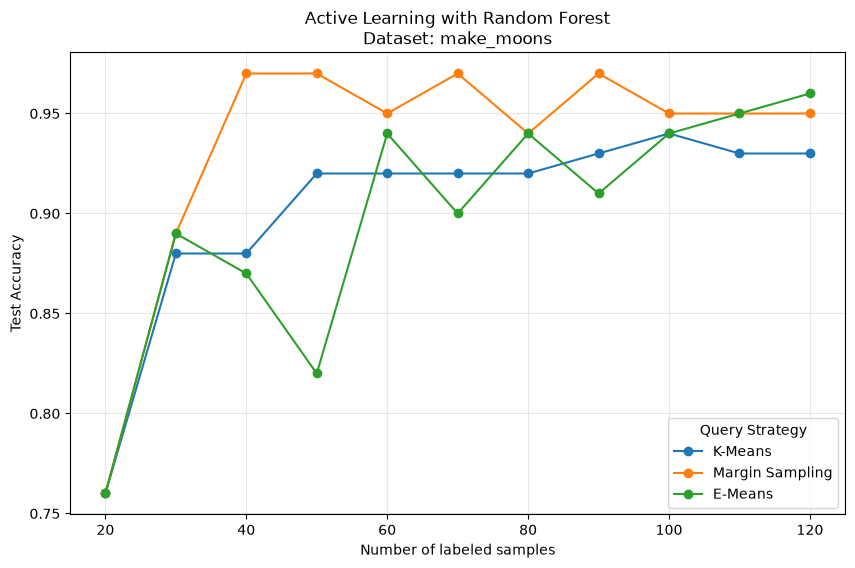

In [27]:
plt.figure(figsize=(10, 6))

for results, label in [
    (results_kmeans, "K-Means"),
    (results_margin, "Margin Sampling"),
    (results_emeans, "E-Means")
]:

    plt.plot(
        [r["labeled_samples"] for r in results],
        [r["accuracy"] for r in results],
        marker="o",
        label=label
    )

plt.xlabel("Number of labeled samples")
plt.ylabel("Test Accuracy")

plt.title(
    "Active Learning with Random Forest\n"
    "Dataset: make_moons"
)

plt.legend(title="Query Strategy")
plt.grid(alpha=0.3)
plt.show()

wichtige Einschränkung: Unsere bisherige EMeansQuery ist eine vereinfachte, am Paper orientierte Implementierung. Wir sollten sie nicht als exakte Reproduktion des vollständigen E-Means-Algorithmus bezeichnen.

AUBC vergleichen

In [28]:
for name, results in [
    ("K-Means", results_kmeans),
    ("Margin Sampling", results_margin),
    ("E-Means", results_emeans)
]:

    x = np.array([r["labeled_samples"] for r in results])
    y_values = np.array([r["accuracy"] for r in results])

    aubc = np.trapezoid(y_values, x)

    print(f"{name}: AUBC = {aubc:.3f}")

K-Means: AUBC = 90.850
Margin Sampling: AUBC = 94.150
E-Means: AUBC = 90.200


K-Means + Margin Sampling
Wie kombinieren wir die beiden Methoden?
Für unseren ersten Versuch wählen wirdie Aufteilung der  Datenpunkte so aus:
- 50 % der Datenpunkte werden durch K-Means ausgewählt.
- 50 % werden durch Margin Sampling ausgewählt.

Hybride Strategie programmieren

In [29]:
class KMeansMarginQuery: #neue Query-Strategie, die K-Means und Margin Sampling kombiniert

    def __init__(self, random_state=42):
        self.kmeans_query = KMeansQuery(
            random_state=random_state
        )
        self.margin_query = MarginSampling()

    def select(self, estimator, pool, n):

        # Hälfte der Datenpunkte durch K-Means
        n_kmeans = n // 2

        # Rest durch Margin Sampling
        n_margin = n - n_kmeans

        # 1. K-Means-Auswahl
        kmeans_indices = self.kmeans_query.select(
            estimator,
            pool,
            n_kmeans
        )

        # 2. Margin Sampling bewertet alle ungelabelten Punkte
        margin_ranking = self.margin_query.select(
            estimator,
            pool,
            pool.n_unlabeled
        )

        # 3. Bereits durch K-Means gewählte Punkte ausschließen
        selected_indices = list(kmeans_indices)

        for idx in margin_ranking:

            if idx not in selected_indices:
                selected_indices.append(idx)

            if len(selected_indices) == n:
                break

        return np.array(selected_indices)

Hybride Strategie testen

In [30]:
hybrid_query = KMeansMarginQuery()

selected_indices_hybrid = hybrid_query.select(
    estimator,
    pool,
    n=10
)

print("Ausgewählte Indizes:", selected_indices_hybrid)

print(
    "Anzahl ausgewählter Datenpunkte:",
    len(selected_indices_hybrid)
)

print(
    "Unterschiedliche Indizes:",
    len(np.unique(selected_indices_hybrid))
)

Ausgewählte Indizes: [271 126  54 171 184   0   1   2   3   4]
Anzahl ausgewählter Datenpunkte: 10
Unterschiedliche Indizes: 10


Eine methodische Anmerkung: Das ist eine sogenannte Batch-Kombination mit festem Verhältnis. Sie ist nicht dasselbe wie unser späterer automatischer Wechsel zwischen K-Means und Margin Sampling. Diesen werden wir separat untersuchen.

Außerdem sollten wir später auch andere Aufteilungen wie 25:75 und 75:25 testen. So können wir feststellen, ob das Verhältnis einen Einfluss auf die Ergebnisse hat.

Hybrid-Strategie vorbereiten und testen

In [ ]:
# Einen frischen Pool erstellen
pool_hybrid_test = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

# Random Forest erstellen
estimator_hybrid_test = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Modell mit den bereits gelabelten Daten trainieren
estimator_hybrid_test.fit(
    pool_hybrid_test.x_labeled,
    pool_hybrid_test.y_labeled
)

# Hybride Strategie testen
hybrid_query = KMeansMarginQuery()

selected_indices_hybrid = hybrid_query.select(
    estimator_hybrid_test,
    pool_hybrid_test,
    n=10
)

print("Ausgewählte Indizes:", selected_indices_hybrid)
print("Anzahl ausgewählter Punkte:", len(selected_indices_hybrid))
print("Anzahl eindeutiger Punkte:", len(np.unique(selected_indices_hybrid)))

Ausgewählte Indizes: [185 321 341 101 232   0   1   2   3   4]
Anzahl ausgewählter Punkte: 10
Anzahl eindeutiger Punkte: 10


Hybride Strategie vollständig ausführen

In [ ]:
# Neuen Pool und Random Forest erstellen
pool_kmeans_margin = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_kmeans_margin = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Ergebnisse speichern
results_kmeans_margin = []

# Active Learning durchführen
for state in active_learning_steps(
    pool_kmeans_margin,
    estimator_kmeans_margin,
    KMeansMarginQuery(),
    query_size=20,
    n_iterations=10
):
    predictions = state.estimator.predict(state.pool.x_test)

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_kmeans_margin.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.840
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.930
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.910
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.900
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.910
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.890
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.890
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.930
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.940
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.940


Alle drei Strategien visualisieren

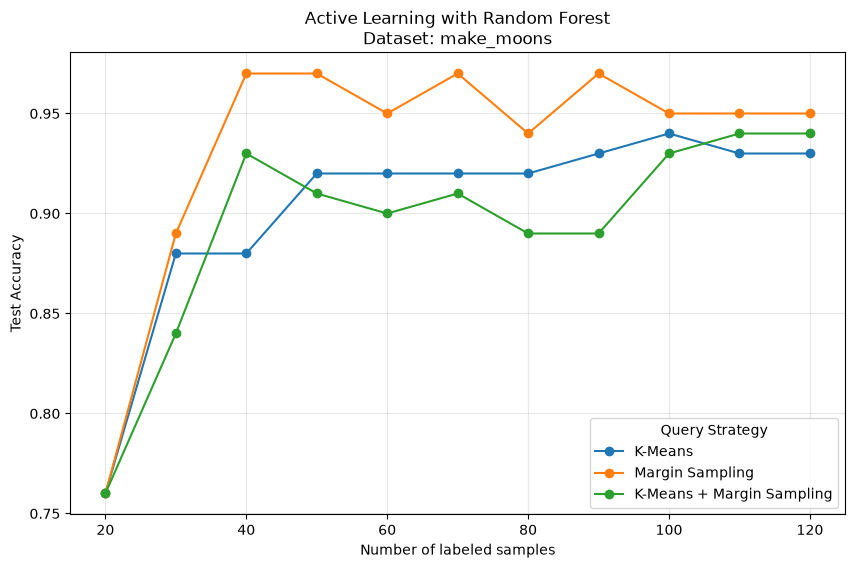

In [33]:
# Daten für die drei Strategien auslesen

x_kmeans = [r["labeled_samples"] for r in results_kmeans]
y_kmeans = [r["accuracy"] for r in results_kmeans]

x_margin = [r["labeled_samples"] for r in results_margin]
y_margin = [r["accuracy"] for r in results_margin]

x_hybrid = [r["labeled_samples"] for r in results_kmeans_margin]
y_hybrid = [r["accuracy"] for r in results_kmeans_margin]


# Diagramm erstellen
plt.figure(figsize=(10, 6))

plt.plot(
    x_kmeans, y_kmeans,
    marker="o",
    label="K-Means"
)

plt.plot(
    x_margin, y_margin,
    marker="o",
    label="Margin Sampling"
)

plt.plot(
    x_hybrid, y_hybrid,
    marker="o",
    label="K-Means + Margin Sampling"
)

plt.xlabel("Number of labeled samples")
plt.ylabel("Test Accuracy")

plt.title(
    "Active Learning with Random Forest\n"
    "Dataset: make_moons"
)

plt.legend(title="Query Strategy")
plt.grid(alpha=0.3)
plt.show()

AUBC für die hybride Strategie berechnen

In [34]:
aubc_kmeans = np.trapezoid(y_kmeans, x_kmeans)
aubc_margin = np.trapezoid(y_margin, x_margin)
aubc_hybrid = np.trapezoid(y_hybrid, x_hybrid)

print("AUBC Comparison")
print("-------------------------")
print(f"K-Means:            {aubc_kmeans:.2f}")
print(f"Margin Sampling:    {aubc_margin:.2f}")
print(f"K-Means + Margin:   {aubc_hybrid:.2f}")

AUBC Comparison
-------------------------
K-Means:            90.85
Margin Sampling:    94.15
K-Means + Margin:   89.90


Je größer die AUBC, desto höher war die durchschnittliche Accuracy über den betrachteten Lernverlauf.

E-Means + Margin Sampling

In [35]:
class EMeansMarginQuery: #neue Query-Strategie, die E-Means und Margin Sampling kombiniert
    def __init__(self, random_state=42):
        self.emeans_query = EMeansQuery(random_state=random_state)
        self.margin_query = MarginSampling()

    def select(self, estimator, pool, n):
        n_emeans = n // 2
        n_margin = n - n_emeans

        # Hälfte der Punkte durch E-Means auswählen
        emeans_indices = self.emeans_query.select(
            estimator, pool, n_emeans
        )

        # Margin Sampling liefert eine Rangfolge
        margin_ranking = self.margin_query.select(
            estimator, pool, pool.n_unlabeled
        )

        selected_indices = list(emeans_indices)

        # Doppelte Indizes vermeiden
        for idx in margin_ranking:
            if idx not in selected_indices:
                selected_indices.append(idx)

            if len(selected_indices) == n:
                break

        return np.array(selected_indices)

Strategie testen

In [ ]:
pool_emeans_test = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_emeans_test = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

estimator_emeans_test.fit(
    pool_emeans_test.x_labeled,
    pool_emeans_test.y_labeled
)

emeans_margin_query = EMeansMarginQuery()

selected_indices = emeans_margin_query.select(
    estimator_emeans_test,
    pool_emeans_test,
    n=10
)

print("Ausgewählte Indizes:", selected_indices)
print("Anzahl ausgewählter Punkte:", len(selected_indices))
print("Eindeutige Punkte:", len(np.unique(selected_indices)))

Ausgewählte Indizes: [105 364 234 335   2   0   1   3   4   5]
Anzahl ausgewählter Punkte: 10
Eindeutige Punkte: 10


E-Means + Margin Sampling vollständig ausführen

In [ ]:
# Neuen Pool und Random Forest erstellen
pool_emeans_margin = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_emeans_margin = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Ergebnisse speichern
results_emeans_margin = []

# Active Learning durchführen
for state in active_learning_steps(
    pool_emeans_margin,
    estimator_emeans_margin,
    EMeansMarginQuery(),
    query_size=20,
    n_iterations=10
):
    predictions = state.estimator.predict(state.pool.x_test)

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_emeans_margin.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.810
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.900
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.910
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.930
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.940
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.940
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.920
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.930
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.920
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.930


Alle bisherigen Strategien vergleichen

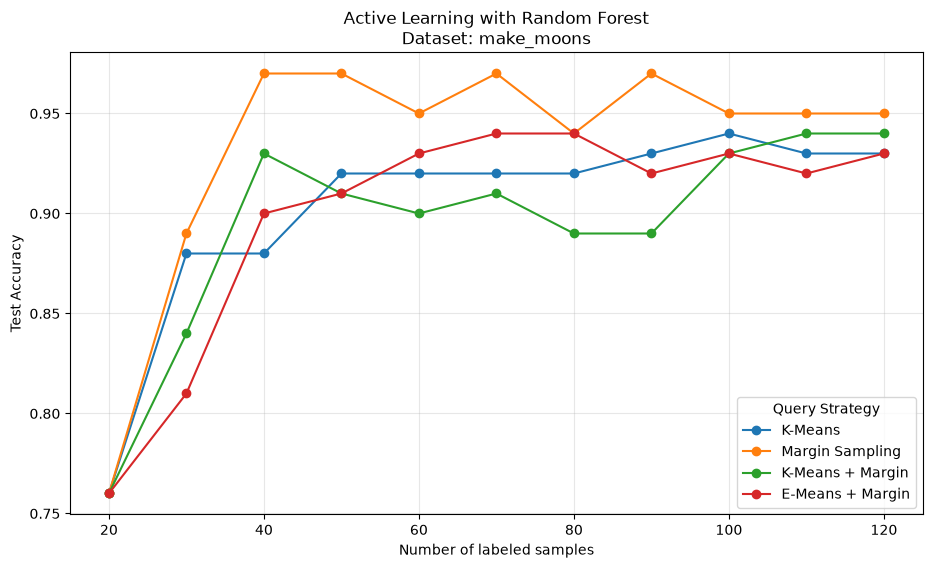

In [39]:
x_emeans_margin = [
    r["labeled_samples"] for r in results_emeans_margin
]

y_emeans_margin = [
    r["accuracy"] for r in results_emeans_margin
]

plt.figure(figsize=(11, 6))

plt.plot(x_kmeans, y_kmeans, marker="o", label="K-Means")
plt.plot(x_margin, y_margin, marker="o", label="Margin Sampling")
plt.plot(
    x_hybrid, y_hybrid,
    marker="o",
    label="K-Means + Margin"
)
plt.plot(
    x_emeans_margin, y_emeans_margin,
    marker="o",
    label="E-Means + Margin"
)

plt.xlabel("Number of labeled samples")
plt.ylabel("Test Accuracy")

plt.title(
    "Active Learning with Random Forest\n"
    "Dataset: make_moons"
)

plt.legend(title="Query Strategy")
plt.grid(alpha=0.3)
plt.show()

AUBC vergleichen

In [40]:
aubc_emeans_margin = np.trapezoid(
    y_emeans_margin,
    x_emeans_margin
)

print("AUBC Comparison")
print("-------------------------")
print(f"K-Means:              {aubc_kmeans:.2f}")
print(f"Margin Sampling:      {aubc_margin:.2f}")
print(f"K-Means + Margin:     {aubc_hybrid:.2f}")
print(f"E-Means + Margin:     {aubc_emeans_margin:.2f}")

AUBC Comparison
-------------------------
K-Means:              90.85
Margin Sampling:      94.15
K-Means + Margin:     89.90
E-Means + Margin:     90.45


Adaptive Query Strategies

Wir wollen nicht mehr pauschal 50 % der Daten mit der einen und 50 % mit der anderen Strategie auswählen. Stattdessen soll unser System selbst entscheiden, wann es von einer Strategie zur anderen wechselt.

Dafür untersuchen wir zunächst zwei mögliche Kriterien:
1. Jensen-Shannon Divergence (JSD): Misst Veränderungen zwischen Wahrscheinlichkeitsverteilungen.
2. Epistemic Uncertainty: Misst die Unsicherheit, die dadurch entsteht, dass dem Modell Wissen bzw. Daten fehlen.

Adaptive K-Means → Margin Sampling mit JSD

Hohe JSD: Die Vorhersagen haben sich stark verändert. Das Modell ist noch nicht stabil.
Niedrige JSD: Die Vorhersagen haben sich wenig verändert. Das Modell wird stabiler.

1. Am Anfang verwenden wir K-Means, um möglichst unterschiedliche Bereiche der Daten abzudecken.
2. Wir beobachten die JSD zwischen den Iterationen.
3. Sobald die JSD über mehrere Iterationen hinweg niedrig bleibt, wechseln wir zu Margin Sampling.

JSD berechnen
Zuerst implementieren wir eine Funktion, die die JSD zwischen zwei Wahrscheinlichkeitsverteilungen berechnet.

In [41]:
def calculate_jsd(p, q, epsilon=1e-10):
    # Kleine Werte verhindern log(0)
    p = np.clip(p, epsilon, 1)
    q = np.clip(q, epsilon, 1)

    # Wahrscheinlichkeiten normalisieren
    p = p / p.sum(axis=1, keepdims=True)
    q = q / q.sum(axis=1, keepdims=True)

    # Mittlere Verteilung
    m = (p + q) / 2

    # KL-Divergenzen berechnen
    kl_pm = np.sum(p * np.log(p / m), axis=1)
    kl_qm = np.sum(q * np.log(q / m), axis=1)

    # JSD pro Datenpunkt
    jsd = (kl_pm + kl_qm) / 2

    # Durchschnitt über alle Datenpunkte
    return np.mean(jsd)

Adaptive Query Strategy implementieren
Jetzt erstellen wir unsere erste adaptive Strategie.

Die Regeln:
- Zunächst verwendet sie K-Means.
- Sie berechnet bei jeder Iteration die JSD.
- Bleibt die JSD zwei Iterationen hintereinander unter 0.01, wechselt sie zu Margin Sampling.
- Nach dem Wechsel bleibt sie bei Margin Sampling.
Wir vergleichen die Vorhersagen immer auf denselben Monitoring-Daten (X_train). Dadurch messen wir Veränderungen auf einer festen Datenbasis und nicht auf einem Pool, der sich ständig verkleinert.

In [42]:
class AdaptiveKMeansMarginJSD:

    def __init__(
        self,
        monitor_X,
        threshold=0.01,
        patience=2,
        random_state=42
    ):
        self.monitor_X = monitor_X
        self.threshold = threshold
        self.patience = patience

        self.kmeans_query = KMeansQuery(
            random_state=random_state
        )

        self.margin_query = MarginSampling()

        self.previous_probs = None
        self.stable_count = 0
        self.switched = False

        self.jsd_history = []
        self.strategy_history = []

    def select(self, estimator, pool, n):

        # Aktuelle Vorhersagewahrscheinlichkeiten
        current_probs = estimator.predict_proba(
            self.monitor_X
        )

        # Beim ersten Durchlauf gibt es noch keinen Vergleich
        if self.previous_probs is None:
            self.previous_probs = current_probs.copy()

            self.strategy_history.append("K-Means")

            return self.kmeans_query.select(
                estimator, pool, n
            )

        # JSD zwischen vorheriger und aktueller Vorhersage
        jsd = calculate_jsd(
            self.previous_probs,
            current_probs
        )

        self.jsd_history.append(jsd)

        # Vorhersagen für die nächste Iteration speichern
        self.previous_probs = current_probs.copy()

        # Prüfen, ob die JSD niedrig genug ist
        if jsd < self.threshold:
            self.stable_count += 1
        else:
            self.stable_count = 0

        # Wechsel zu Margin Sampling
        if self.stable_count >= self.patience:
            self.switched = True

        # Strategie auswählen
        if self.switched:
            self.strategy_history.append("Margin Sampling")

            return self.margin_query.select(
                estimator, pool, n
            )

        else:
            self.strategy_history.append("K-Means")

            return self.kmeans_query.select(
                estimator, pool, n
            )

Klasse besitzt einige wichtige Variablen:
| Variable | Bedeutung |
|---|---|
| `previous_probs` | Vorhersagen aus der vorherigen Iteration |
| `jsd_history` | Speichert die berechneten JSD-Werte |
| `stable_count` | Zählt aufeinanderfolgende Iterationen mit niedriger JSD |
| `threshold` | Grenzwert für die JSD |
| `patience` | Wie oft der Grenzwert unterschritten werden muss |
| `switched` | Speichert, ob bereits gewechselt wurde |

adaptive Strategie testen

In [ ]:
pool_adaptive_jsd = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_adaptive_jsd = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

adaptive_jsd = AdaptiveKMeansMarginJSD(
    monitor_X=X_train,
    threshold=0.01,
    patience=2,
    random_state=42
)

results_adaptive_jsd = []

for state in active_learning_steps(
    pool_adaptive_jsd,
    estimator_adaptive_jsd,
    adaptive_jsd,
    query_size=20,
    n_iterations=10
):

    predictions = state.estimator.predict(
        state.pool.x_test
    )

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_adaptive_jsd.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.880
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.880
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.920
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.920
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.970
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.930
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.940
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.940
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.940
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.940


Wechselzeitpunkt überprüfen

In [44]:
print("Strategie pro Iteration:")
for i, strategy in enumerate(adaptive_jsd.strategy_history):
    print(f"Iteration {i}: {strategy}")

print("\nJSD-Werte:")
for i, jsd in enumerate(adaptive_jsd.jsd_history):
    print(f"Iteration {i + 1}: {jsd:.6f}")

Strategie pro Iteration:
Iteration 0: K-Means
Iteration 1: K-Means
Iteration 2: K-Means
Iteration 3: Margin Sampling
Iteration 4: Margin Sampling
Iteration 5: Margin Sampling
Iteration 6: Margin Sampling
Iteration 7: Margin Sampling
Iteration 8: Margin Sampling
Iteration 9: Margin Sampling

JSD-Werte:
Iteration 1: 0.012605
Iteration 2: 0.006493
Iteration 3: 0.004858
Iteration 4: 0.007226
Iteration 5: 0.008906
Iteration 6: 0.011394
Iteration 7: 0.009206
Iteration 8: 0.004166
Iteration 9: 0.002851


JSD-Verlauf visualisieren

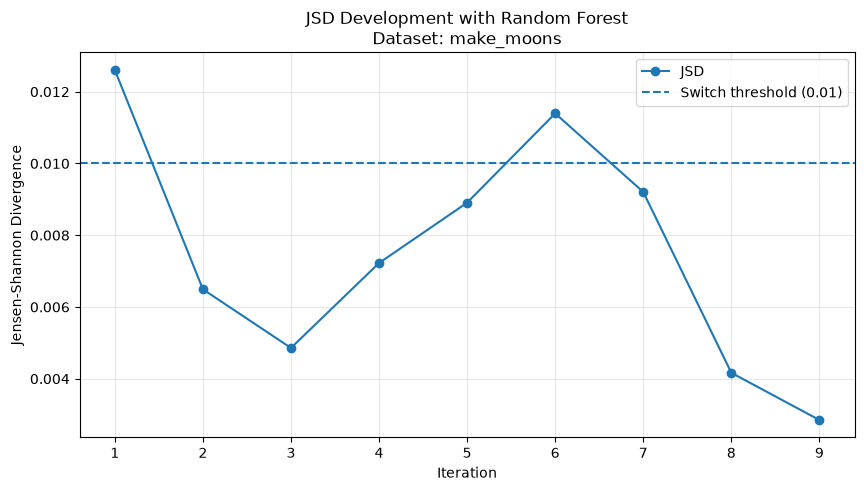

In [45]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(adaptive_jsd.jsd_history) + 1),
    adaptive_jsd.jsd_history,
    marker="o",
    label="JSD"
)

plt.axhline(
    y=0.01,
    linestyle="--",
    label="Switch threshold (0.01)"
)

plt.xlabel("Iteration")
plt.ylabel("Jensen-Shannon Divergence")
plt.title(
    "JSD Development with Random Forest\n"
    "Dataset: make_moons"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Wechselzeitpunkt überprüfen

In [46]:
print("Strategie bei jeder Auswahl:")
for i, strategy in enumerate(adaptive_jsd.strategy_history):
    print(f"Auswahl {i + 1}: {strategy}")

print("\nJSD-Werte:")
for i, jsd in enumerate(adaptive_jsd.jsd_history):
    print(f"Iteration {i + 1}: {jsd:.6f}")

print("\nWurde gewechselt?", adaptive_jsd.switched)

Strategie bei jeder Auswahl:
Auswahl 1: K-Means
Auswahl 2: K-Means
Auswahl 3: K-Means
Auswahl 4: Margin Sampling
Auswahl 5: Margin Sampling
Auswahl 6: Margin Sampling
Auswahl 7: Margin Sampling
Auswahl 8: Margin Sampling
Auswahl 9: Margin Sampling
Auswahl 10: Margin Sampling

JSD-Werte:
Iteration 1: 0.012605
Iteration 2: 0.006493
Iteration 3: 0.004858
Iteration 4: 0.007226
Iteration 5: 0.008906
Iteration 6: 0.011394
Iteration 7: 0.009206
Iteration 8: 0.004166
Iteration 9: 0.002851

Wurde gewechselt? True


Adaptive E-Means + Margin Sampling

Adaptive Strategie implementieren

In [47]:
class AdaptiveEMeansMarginJSD:

    def __init__(
        self,
        monitor_X,
        threshold=0.01,
        patience=2,
        random_state=42
    ):
        self.monitor_X = monitor_X
        self.threshold = threshold
        self.patience = patience

        self.emeans_query = EMeansQuery(
            random_state=random_state
        )

        self.margin_query = MarginSampling()

        self.previous_probs = None
        self.stable_count = 0
        self.switched = False

        self.jsd_history = []
        self.strategy_history = []

    def select(self, estimator, pool, n):

        current_probs = estimator.predict_proba(
            self.monitor_X
        )

        # Erster Durchlauf
        if self.previous_probs is None:
            self.previous_probs = current_probs.copy()

            self.strategy_history.append("E-Means")

            return self.emeans_query.select(
                estimator, pool, n
            )

        # JSD berechnen
        jsd = calculate_jsd(
            self.previous_probs,
            current_probs
        )

        self.jsd_history.append(jsd)

        self.previous_probs = current_probs.copy()

        # Stabilität überprüfen
        if jsd < self.threshold:
            self.stable_count += 1
        else:
            self.stable_count = 0

        # Bei ausreichender Stabilität wechseln
        if self.stable_count >= self.patience:
            self.switched = True

        # Strategie auswählen
        if self.switched:
            self.strategy_history.append("Margin Sampling")

            return self.margin_query.select(
                estimator, pool, n
            )

        else:
            self.strategy_history.append("E-Means")

            return self.emeans_query.select(
                estimator, pool, n
            )

Active Learning durchführen

In [ ]:
pool_adaptive_emeans = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_adaptive_emeans = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

adaptive_emeans_jsd = AdaptiveEMeansMarginJSD(
    monitor_X=X_train,
    threshold=0.01,
    patience=2,
    random_state=42
)

results_adaptive_emeans_jsd = []

for state in active_learning_steps(
    pool_adaptive_emeans,
    estimator_adaptive_emeans,
    adaptive_emeans_jsd,
    query_size=20,
    n_iterations=10
):

    predictions = state.estimator.predict(
        state.pool.x_test
    )

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_adaptive_emeans_jsd.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.890
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.870
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.820
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.950
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.940
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.970
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.950
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.960
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.950
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.950


Wechselzeitpunkt überprüfen

In [49]:
print("Strategie pro Auswahl:")

for i, strategy in enumerate(
    adaptive_emeans_jsd.strategy_history
):
    print(f"Auswahl {i + 1}: {strategy}")

print("\nJSD-Werte:")

for i, jsd in enumerate(
    adaptive_emeans_jsd.jsd_history
):
    print(f"Iteration {i + 1}: {jsd:.6f}")

print("\nWurde gewechselt?", adaptive_emeans_jsd.switched)

Strategie pro Auswahl:
Auswahl 1: E-Means
Auswahl 2: E-Means
Auswahl 3: E-Means
Auswahl 4: Margin Sampling
Auswahl 5: Margin Sampling
Auswahl 6: Margin Sampling
Auswahl 7: Margin Sampling
Auswahl 8: Margin Sampling
Auswahl 9: Margin Sampling
Auswahl 10: Margin Sampling

JSD-Werte:
Iteration 1: 0.012829
Iteration 2: 0.003026
Iteration 3: 0.004053
Iteration 4: 0.010998
Iteration 5: 0.009903
Iteration 6: 0.008061
Iteration 7: 0.006605
Iteration 8: 0.004168
Iteration 9: 0.005061

Wurde gewechselt? True


JSD-Verlauf visualisieren

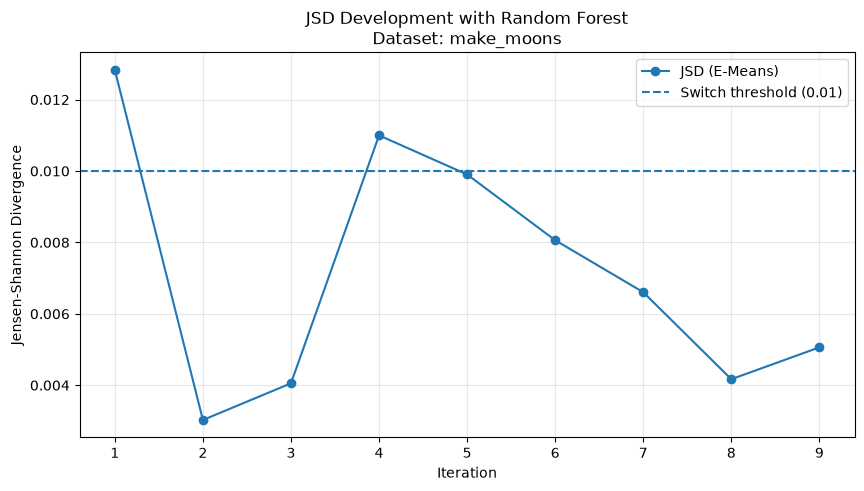

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(adaptive_emeans_jsd.jsd_history) + 1),
    adaptive_emeans_jsd.jsd_history,
    marker="o",
    label="JSD (E-Means)"
)

plt.axhline(
    y=0.01,
    linestyle="--",
    label="Switch threshold (0.01)"
)

plt.xlabel("Iteration")
plt.ylabel("Jensen-Shannon Divergence")

plt.title(
    "JSD Development with Random Forest\n"
    "Dataset: make_moons"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Adaptive Strategien mit Epistemic Uncertainty

1. Wir beginnen mit K-Means.
2. Wir beobachten die epistemische Unsicherheit.
3. Wenn sie ausreichend gesunken ist, wechseln wir zu Margin Sampling.

???: Ein Random Forest besteht aus vielen einzelnen Decision Trees.
Jeder Tree trifft eigene Vorhersagen. Wenn die Trees bei einem Datenpunkt stark unterschiedliche Wahrscheinlichkeiten vorhersagen, deutet das auf Unsicherheit innerhalb des Modells hin.
Wir verwenden deshalb die **Varianz der Vorhersagewahrscheinlichkeiten zwischen den Trees** als Näherung für epistemische Unsicherheit. 

--> wäre eine Möglichkeit aber wir nutzen stattdessen decompose() von probly

In [53]:
import importlib.metadata
import probly

print("Probly version:")
print(importlib.metadata.version("probly"))

print("\nAvailable uncertainty methods:")

import probly.evaluation.active_learning.strategies as strategies

print([
    name for name in dir(strategies)
    if "Uncertainty" in name or "Entropy" in name
])

Probly version:
0.9.2.dev65+gc17d796f3

Available uncertainty methods:
['EntropySampling', 'UncertaintyEstimator', 'UncertaintyQuery']


In [54]:
import probly.quantification as quantification
import probly.representer as representer
import probly.method as method

print("QUANTIFICATION:")
print([x for x in dir(quantification) if not x.startswith("_")])

print("\nREPRESENTER:")
print([x for x in dir(representer) if not x.startswith("_")])

print("\nMETHOD:")
print([x for x in dir(method) if not x.startswith("_")])

QUANTIFICATION:
['AdditiveDecomposition', 'AleatoricDecomposition', 'AleatoricEpistemicDecomposition', 'AleatoricEpistemicTotalDecomposition', 'AleatoricUncertainty', 'BrierLoss', 'CachingDecomposition', 'CategoricalVarianceDecomposition', 'CredalSetEntropyDecomposition', 'Decomposition', 'EpistemicDecomposition', 'EpistemicUncertainty', 'LabelwiseBinaryEntropyDecomposition', 'LabelwiseBinaryVarianceDecomposition', 'LogLoss', 'Notion', 'OrdinalEntropyDecomposition', 'OrdinalVarianceDecomposition', 'QuantificationResult', 'Quantifier', 'ScoringRule', 'SecondOrderEntropyDecomposition', 'SecondOrderScoringRuleDecomposition', 'SecondOrderVarianceDecomposition', 'SecondOrderWassersteinDecomposition', 'SecondOrderZeroOneDecomposition', 'SphericalLoss', 'TotalDecomposition', 'TotalUncertainty', 'ZeroOneLoss', 'conditional_entropy', 'conditional_spectral_entropy', 'conformal_set_size', 'decompose', 'decomposition', 'dempster_shafer_uncertainty', 'entropy', 'entropy_of_expected_predictive_distr

In [55]:
import inspect

from probly.method import ensemble
from probly.representer import representer
from probly.quantification import decompose, quantify

print("ENSEMBLE:")
print(inspect.signature(ensemble))

print("\nREPRESENTER:")
print(inspect.signature(representer))

print("\nDECOMPOSE:")
print(inspect.signature(decompose))

print("\nQUANTIFY:")
print(inspect.signature(quantify))

ENSEMBLE:
(base: 'Predictor[In, Out]', num_members: 'int', reset_params: 'bool' = True) -> 'EnsemblePredictor[In, Out]'

REPRESENTER:
(predictor: 'Predictor[In, Out]', *args: 'CtrIn.args', **kwargs: 'CtrIn.kwargs') -> 'Representer[CtrIn, In, Out, R]'

DECOMPOSE:
(representation: 'Representation', *args: 'Any', **kwargs: 'Any') -> 'Decomposition'

QUANTIFY:
(representation: 'Representation', *args: 'Any', **kwargs: 'Any') -> 'QuantificationResult'


Wir prüfen, wie Probly seine Repräsentationen aufbaut

In [56]:
import probly.representation as representation

print("Available representations:")

print([
    name for name in dir(representation)
    if not name.startswith("_")
])

Available representations:
['CategoricalCredalSet', 'CredalSet', 'CredalSetType', 'DiscreteCredalSet', 'NumpyCategoricalCredalSet', 'NumpyDiscreteCredalSet', 'Representation', 'Sample', 'conformal_set', 'credal_set', 'distribution', 'embedding', 'representation', 'sample']


Die Second-Order-Quantifizierung genauer untersuchen

In [57]:
from probly.quantification import SecondOrderEntropyDecomposition

import inspect

print(inspect.signature(SecondOrderEntropyDecomposition))

print(inspect.getdoc(SecondOrderEntropyDecomposition))

(distribution: 'SecondOrderDistributionLike', base: 'LogBase' = None) -> None
Base class for entropy-based decomposition methods.


In [58]:
from probly.representation.distribution import (
    create_categorical_distribution
)

from probly.representation.sample import create_sample

from probly.quantification import decompose

Vorhersagen aller Trees sammeln

In [59]:
# Vorhersagen auf unseren Monitoring-Daten sammeln
all_tree_predictions = []

for tree in test_estimator.estimators_:

    tree_probs = np.zeros(
        (len(X_train), len(test_estimator.classes_))
    )

    probabilities = tree.predict_proba(X_train)

    # Klassen in die richtige Reihenfolge bringen
    for j, class_label in enumerate(tree.classes_):

        class_index = np.where(
            test_estimator.classes_ == class_label
        )[0][0]

        tree_probs[:, class_index] = probabilities[:, j]

    all_tree_predictions.append(tree_probs)

print("Number of trees:", len(all_tree_predictions))
print("Shape of one prediction:", all_tree_predictions[0].shape)

Number of trees: 100
Shape of one prediction: (400, 2)


Probly-Repräsentation erstellen

In [60]:
# Aus jeder Tree-Vorhersage eine Wahrscheinlichkeitsverteilung erstellen
tree_distributions = [
    create_categorical_distribution(predictions)
    for predictions in all_tree_predictions
]

# Alle Verteilungen zu einem Sample zusammenfassen
tree_sample = create_sample(
    tree_distributions,
    sample_axis=0
)

print("Number of members:", tree_sample.sample_size)
print(
    "Mean prediction shape:",
    tree_sample.sample_mean().probabilities.shape
)

Number of members: 100
Mean prediction shape: (400, 2)


Damit haben wir eine Second-Order Representation erstellt.

Unsicherheit mit Probly zerlegen

In [61]:
uncertainty = decompose(tree_sample)

epistemic_values = uncertainty.epistemic
aleatoric_values = uncertainty.aleatoric
total_values = uncertainty.total

print("Average Epistemic Uncertainty:",
      np.mean(epistemic_values))

print("Average Aleatoric Uncertainty:",
      np.mean(aleatoric_values))

print("Average Total Uncertainty:",
      np.mean(total_values))

Average Epistemic Uncertainty: 0.3310523305797807
Average Aleatoric Uncertainty: 0.0
Average Total Uncertainty: 0.33105233057978084


Erkenntnis aus der Probly-Dokumentation: 
Bei einer Second-Order-Sample wird die Streuung zwischen den Vorhersageverteilungen als epistemische Unsicherheit und die durchschnittliche Unsicherheit innerhalb der Verteilungen als aleatorische Unsicherheit interpretiert. pwhofman.github.io

Eine wiederverwendbare Probly-Funktion erstellen

In [62]:
from probly.representation.distribution import (
    create_categorical_distribution
)

from probly.representation.sample import create_sample

from probly.quantification import decompose


def calculate_probly_uncertainty(estimator, X):

    all_tree_predictions = []

    # Vorhersagen aller Random-Forest-Trees sammeln
    for tree in estimator.estimators_:

        probabilities = tree.predict_proba(X)

        tree_probs = np.zeros(
            (len(X), len(estimator.classes_))
        )

        # Klassen richtig zuordnen
        for j, class_label in enumerate(tree.classes_):

            class_index = np.where(
                estimator.classes_ == class_label
            )[0][0]

            tree_probs[:, class_index] = probabilities[:, j]

        all_tree_predictions.append(tree_probs)

    # Probly-Repräsentation erstellen
    distributions = [
        create_categorical_distribution(predictions)
        for predictions in all_tree_predictions
    ]

    sample = create_sample(
        distributions,
        sample_axis=0
    )

    # Unsicherheit zerlegen
    uncertainty = decompose(sample)

    return {
        "epistemic": np.mean(uncertainty.epistemic),
        "aleatoric": np.mean(uncertainty.aleatoric),
        "total": np.mean(uncertainty.total)
    }

Funktion testen

In [63]:
probly_uncertainty = calculate_probly_uncertainty(
    test_estimator,
    X_train
)

print("Probly Uncertainty")
print("--------------------------")

print(
    "Epistemic:",
    probly_uncertainty["epistemic"]
)

print(
    "Aleatoric:",
    probly_uncertainty["aleatoric"]
)

print(
    "Total:",
    probly_uncertainty["total"]
)

Probly Uncertainty
--------------------------
Epistemic: 0.3310523305797807
Aleatoric: 0.0
Total: 0.33105233057978084


Adaptive Strategie mit Probly

K-Means → Margin Sampling mit Probly
Unsere Wechselregel bleibt zunächst dieselbe:
1. Wir starten mit K-Means.
2. Probly berechnet die epistemische Unsicherheit.
3. Wir vergleichen sie mit dem ursprünglichen Wert.
4. Sobald sie mindestens 20 % gesunken ist und zwei Iterationen hintereinander unter dem Grenzwert bleibt, wechseln wir zu Margin Sampling.

In [64]:
class AdaptiveKMeansMarginProbly:

    def __init__(
        self,
        monitor_X,
        reduction_fraction=0.20,
        patience=2,
        random_state=42
    ):
        self.monitor_X = monitor_X
        self.reduction_fraction = reduction_fraction
        self.patience = patience

        self.kmeans_query = KMeansQuery(
            random_state=random_state
        )

        self.margin_query = MarginSampling()

        self.initial_uncertainty = None
        self.threshold = None

        self.stable_count = 0
        self.switched = False

        self.uncertainty_history = []
        self.aleatoric_history = []
        self.total_history = []
        self.strategy_history = []

    def select(self, estimator, pool, n):

        # Unsicherheit mit Probly berechnen
        uncertainty = calculate_probly_uncertainty(
            estimator,
            self.monitor_X
        )

        epistemic = uncertainty["epistemic"]
        aleatoric = uncertainty["aleatoric"]
        total = uncertainty["total"]

        self.uncertainty_history.append(epistemic)
        self.aleatoric_history.append(aleatoric)
        self.total_history.append(total)

        # Ausgangswert beim ersten Durchlauf speichern
        if self.initial_uncertainty is None:

            self.initial_uncertainty = epistemic

            self.threshold = (
                epistemic * (1 - self.reduction_fraction)
            )

        # Prüfen, ob die epistemische Unsicherheit gesunken ist
        if epistemic < self.threshold:
            self.stable_count += 1
        else:
            self.stable_count = 0

        # Strategie wechseln
        if self.stable_count >= self.patience:
            self.switched = True

        if self.switched:

            self.strategy_history.append("Margin Sampling")

            return self.margin_query.select(
                estimator, pool, n
            )

        else:

            self.strategy_history.append("K-Means")

            return self.kmeans_query.select(
                estimator, pool, n
            )

Active Learning durchführen

In [ ]:
pool_adaptive_probly = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_adaptive_probly = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

adaptive_probly = AdaptiveKMeansMarginProbly(
    monitor_X=X_train,
    reduction_fraction=0.20,
    patience=2,
    random_state=42
)

results_adaptive_probly = []

for state in active_learning_steps(
    pool_adaptive_probly,
    estimator_adaptive_probly,
    adaptive_probly,
    query_size=20,
    n_iterations=10
):

    predictions = state.estimator.predict(
        state.pool.x_test
    )

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_adaptive_probly.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.880
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.880
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.920
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.920
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.970
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.930
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.940
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.940
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.940
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.940


Wechselzeitpunkt untersuchen

In [66]:
print("Initial epistemic uncertainty:",
      adaptive_probly.initial_uncertainty)

print("Switch threshold:",
      adaptive_probly.threshold)

print("\nEpistemic Uncertainty:")

for i, value in enumerate(
    adaptive_probly.uncertainty_history
):
    print(f"Iteration {i}: {value:.6f}")

print("\nStrategy per selection:")

for i, strategy in enumerate(
    adaptive_probly.strategy_history
):
    print(f"Selection {i + 1}: {strategy}")

print("\nSwitched:", adaptive_probly.switched)

Initial epistemic uncertainty: 0.3310523305797807
Switch threshold: 0.2648418644638246

Epistemic Uncertainty:
Iteration 0: 0.331052
Iteration 1: 0.318374
Iteration 2: 0.262469
Iteration 3: 0.248494
Iteration 4: 0.243774
Iteration 5: 0.252245
Iteration 6: 0.256372
Iteration 7: 0.198273
Iteration 8: 0.196328
Iteration 9: 0.162226

Strategy per selection:
Selection 1: K-Means
Selection 2: K-Means
Selection 3: K-Means
Selection 4: Margin Sampling
Selection 5: Margin Sampling
Selection 6: Margin Sampling
Selection 7: Margin Sampling
Selection 8: Margin Sampling
Selection 9: Margin Sampling
Selection 10: Margin Sampling

Switched: True


Damit sehen wir, ob die epistemische Unsicherheit tatsächlich um mindestens 20 % gesunken ist und unser System zu Margin Sampling gewechselt hat.

Adaptive E-Means → Margin Sampling mit Probly

Adaptive Klasse erstellen
Die Logik bleibt identisch zu unserer K-

In [67]:
class AdaptiveEMeansMarginProbly:

    def __init__(
        self,
        monitor_X,
        reduction_fraction=0.20,
        patience=2,
        random_state=42
    ):
        self.monitor_X = monitor_X
        self.reduction_fraction = reduction_fraction
        self.patience = patience

        self.emeans_query = EMeansQuery(
            random_state=random_state
        )

        self.margin_query = MarginSampling()

        self.initial_uncertainty = None
        self.threshold = None

        self.stable_count = 0
        self.switched = False

        self.uncertainty_history = []
        self.aleatoric_history = []
        self.total_history = []
        self.strategy_history = []

    def select(self, estimator, pool, n):

        # Unsicherheit mit Probly berechnen
        uncertainty = calculate_probly_uncertainty(
            estimator,
            self.monitor_X
        )

        epistemic = uncertainty["epistemic"]
        aleatoric = uncertainty["aleatoric"]
        total = uncertainty["total"]

        self.uncertainty_history.append(epistemic)
        self.aleatoric_history.append(aleatoric)
        self.total_history.append(total)

        # Ausgangswert speichern
        if self.initial_uncertainty is None:

            self.initial_uncertainty = epistemic

            self.threshold = (
                epistemic * (1 - self.reduction_fraction)
            )

        # Stabilität überprüfen
        if epistemic < self.threshold:
            self.stable_count += 1
        else:
            self.stable_count = 0

        # Wechsel auslösen
        if self.stable_count >= self.patience:
            self.switched = True

        # Strategie auswählen
        if self.switched:

            self.strategy_history.append("Margin Sampling")

            return self.margin_query.select(
                estimator, pool, n
            )

        else:

            self.strategy_history.append("E-Means")

            return self.emeans_query.select(
                estimator, pool, n
            )

Active Learning durchführen

In [ ]:
pool_adaptive_emeans_probly = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_adaptive_emeans_probly = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

adaptive_emeans_probly = AdaptiveEMeansMarginProbly(
    monitor_X=X_train,
    reduction_fraction=0.20,
    patience=2,
    random_state=42
)

results_adaptive_emeans_probly = []

for state in active_learning_steps(
    pool_adaptive_emeans_probly,
    estimator_adaptive_emeans_probly,
    adaptive_emeans_probly,
    query_size=20,
    n_iterations=10
):

    predictions = state.estimator.predict(
        state.pool.x_test
    )

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_adaptive_emeans_probly.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.890
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.870
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.820
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.940
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.950
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.970
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.960
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.960
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.960
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.950


Wechselzeitpunkt untersuchen

In [69]:
print("Initial epistemic uncertainty:",
      adaptive_emeans_probly.initial_uncertainty)

print("Switch threshold:",
      adaptive_emeans_probly.threshold)

print("\nEpistemic Uncertainty:")

for i, value in enumerate(
    adaptive_emeans_probly.uncertainty_history
):
    print(f"Iteration {i}: {value:.6f}")

print("\nStrategy per selection:")

for i, strategy in enumerate(
    adaptive_emeans_probly.strategy_history
):
    print(f"Selection {i + 1}: {strategy}")

print("\nSwitched:", adaptive_emeans_probly.switched)

Initial epistemic uncertainty: 0.3310523305797807
Switch threshold: 0.2648418644638246

Epistemic Uncertainty:
Iteration 0: 0.331052
Iteration 1: 0.324276
Iteration 2: 0.301540
Iteration 3: 0.259073
Iteration 4: 0.247757
Iteration 5: 0.231495
Iteration 6: 0.229668
Iteration 7: 0.215283
Iteration 8: 0.186994
Iteration 9: 0.151368

Strategy per selection:
Selection 1: E-Means
Selection 2: E-Means
Selection 3: E-Means
Selection 4: E-Means
Selection 5: Margin Sampling
Selection 6: Margin Sampling
Selection 7: Margin Sampling
Selection 8: Margin Sampling
Selection 9: Margin Sampling
Selection 10: Margin Sampling

Switched: True


Eine wichtige Einschränkung für die spätere Auswertung: Wir haben bisher nur einzelne Durchläufe mit einem festen Seed. Für belastbare Aussagen müssen wir die Strategien später mit mehreren Seeds wiederholen. Außerdem sollten wir prüfen, ob die Probly-Epistemic-Werte tatsächlich aussagekräftig auf die Änderungen im Modell reagieren.

Alle Strategien miteinander vergleichen

Random Sampling als Baseline ergänzen

In [ ]:
pool_random = from_dataset(
    X_train, y_train,
    X_test, y_test,
    initial_size=30,
    seed=42
)

estimator_random = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

results_random = []

for state in active_learning_steps(
    pool_random,
    estimator_random,
    RandomQuery(),
    query_size=20,
    n_iterations=10
):

    predictions = state.estimator.predict(state.pool.x_test)

    accuracy = compute_accuracy(
        predictions,
        state.pool.y_test
    )

    results_random.append({
        "iteration": state.iteration,
        "labeled_samples": state.pool.n_labeled,
        "accuracy": accuracy
    })

    print(
        f"Iteration: {state.iteration} | "
        f"Labeled samples: {state.pool.n_labeled} | "
        f"Accuracy: {accuracy:.3f}"
    )

Iteration: 0 | Labeled samples: 20 | Accuracy: 0.760
Iteration: 1 | Labeled samples: 30 | Accuracy: 0.820
Iteration: 2 | Labeled samples: 40 | Accuracy: 0.820
Iteration: 3 | Labeled samples: 50 | Accuracy: 0.820
Iteration: 4 | Labeled samples: 60 | Accuracy: 0.830
Iteration: 5 | Labeled samples: 70 | Accuracy: 0.860
Iteration: 6 | Labeled samples: 80 | Accuracy: 0.930
Iteration: 7 | Labeled samples: 90 | Accuracy: 0.930
Iteration: 8 | Labeled samples: 100 | Accuracy: 0.950
Iteration: 9 | Labeled samples: 110 | Accuracy: 0.980
Iteration: 10 | Labeled samples: 120 | Accuracy: 0.970


Alle zehn Strategien visualisieren
| Kategorie | Strategie |
|---|---|
| Baseline | Random Sampling |
| Einzelstrategie | K-Means |
| Einzelstrategie | E-Means |
| Einzelstrategie | Margin Sampling |
| Hybrid | K-Means + Margin |
| Hybrid | E-Means + Margin |
| Adaptiv (JSD) | K-Means → Margin |
| Adaptiv (JSD) | E-Means → Margin |
| Adaptiv (Probly) | K-Means → Margin |
| Adaptiv (Probly) | E-Means → Margin |

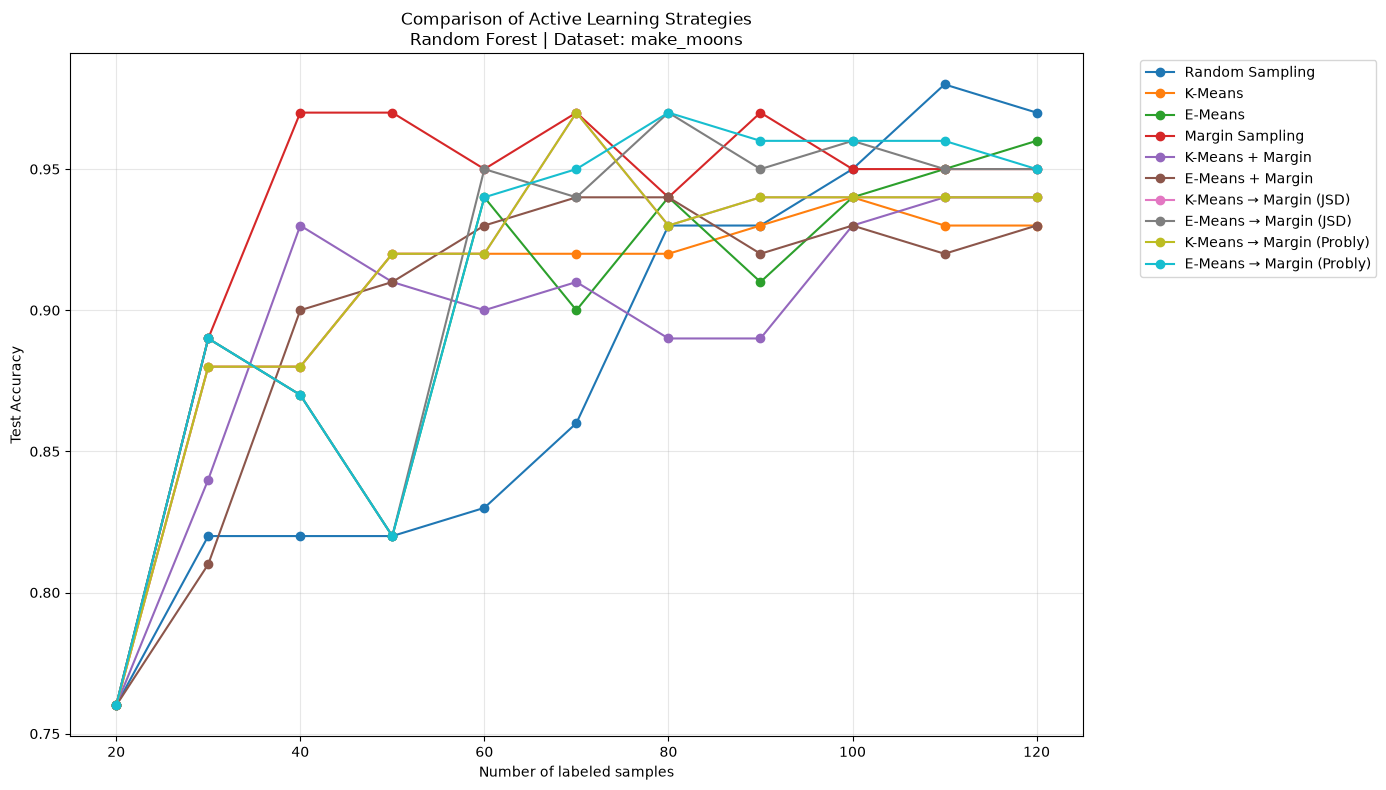

In [71]:
all_results = {
    "Random Sampling": results_random,
    "K-Means": results_kmeans,
    "E-Means": results_emeans,
    "Margin Sampling": results_margin,
    "K-Means + Margin": results_kmeans_margin,
    "E-Means + Margin": results_emeans_margin,
    "K-Means → Margin (JSD)": results_adaptive_jsd,
    "E-Means → Margin (JSD)": results_adaptive_emeans_jsd,
    "K-Means → Margin (Probly)": results_adaptive_probly,
    "E-Means → Margin (Probly)": results_adaptive_emeans_probly
}

plt.figure(figsize=(14, 8))

for name, results in all_results.items():

    x = [r["labeled_samples"] for r in results]
    y = [r["accuracy"] for r in results]

    plt.plot(
        x, y,
        marker="o",
        label=name
    )

plt.xlabel("Number of labeled samples")
plt.ylabel("Test Accuracy")

plt.title(
    "Comparison of Active Learning Strategies\n"
    "Random Forest | Dataset: make_moons"
)

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

AUBC für alle Strategien berechnen

In [72]:
aubc_results = {}

for name, results in all_results.items():

    x = np.array([r["labeled_samples"] for r in results])
    y = np.array([r["accuracy"] for r in results])

    aubc_results[name] = np.trapezoid(y, x)

print("AUBC Comparison")
print("=" * 50)

for name, value in sorted(
    aubc_results.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name:35s} {value:.2f}")

AUBC Comparison
Margin Sampling                     94.15
E-Means → Margin (Probly)           91.75
K-Means → Margin (JSD)              91.70
K-Means → Margin (Probly)           91.70
E-Means → Margin (JSD)              91.55
K-Means                             90.85
E-Means + Margin                    90.45
E-Means                             90.20
K-Means + Margin                    89.90
Random Sampling                     88.05


⚠️ Eine wichtige methodische Einschränkung
Bevor wir aus den Ergebnissen Schlussfolgerungen ziehen, müssen wir noch Folgendes berücksichtigen:
- Bisher verwenden wir nur einen Seed.
- Unsere E-Means-Implementierung ist vereinfacht.
- Die Wechselgrenzen 0.01 und 20 % sind zunächst experimentell gewählt.
- Wir müssen prüfen, ob die unterschiedlichen Strategien tatsächlich vergleichbar implementiert sind.
Für belastbare Ergebnisse sollten wir später mehrere Seeds testen und Mittelwerte sowie Streuungen vergleichen.

ECE (Expected Calibration Error) – Wie gut kann das Modell seiner eigenen Sicherheit vertrauen?
Niedrige ECE: Die vorhergesagte Sicherheit passt gut zur tatsächlichen Trefferquote.
Hohe ECE: Das Modell ist schlecht kalibriert, beispielsweise häufig zu selbstsicher.

ECE und Error Detection AUROC für jede Iteration deiner bisherigen Experimente

In [73]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score

ECE-Funktion erstellen
Die ECE berechnet, wie stark die vorhergesagte Konfidenz von der tatsächlichen Trefferquote abweicht.

In [74]:
def calculate_ece(y_true, probabilities, n_bins=10):
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    correct = (predictions == y_true)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        mask = (confidence > bin_edges[i]) & (confidence <= bin_edges[i + 1])

        if np.sum(mask) > 0:
            bin_accuracy = np.mean(correct[mask])
            bin_confidence = np.mean(confidence[mask])
            bin_weight = np.mean(mask)

            ece += bin_weight * abs(bin_accuracy - bin_confidence)

    return ece

Was macht die Funktion?
1. Sie ermittelt die vorhergesagte Klasse.
2. Sie ermittelt die Konfidenz jeder Vorhersage.
3. Sie teilt die Vorhersagen in zehn Konfidenzgruppen ein.
4. Sie vergleicht für jede Gruppe die durchschnittliche Konfidenz mit der tatsächlichen Accuracy.

Error Detection AUROC
Hier behandeln wir falsche Vorhersagen als positive Fälle. Ein Modell sollte ihnen möglichst niedrige Konfidenzen zuordnen.

In [75]:
def calculate_error_auroc(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    errors = (predictions != y_true)

    if len(np.unique(errors)) < 2:
        return np.nan

    return roc_auc_score(errors, 1 - confidence)

Warum 1 - confidence?

Weil wir Fehler erkennen möchten:
- Niedrige Konfidenz → hoher Error Score.
- Hohe Konfidenz → niedriger Error Score.
Ein hoher AUROC-Wert bedeutet, dass Fehler und korrekte Vorhersagen gut anhand der Konfidenz unterschieden werden können.

Beide Kennzahlen in einer Iteration testen

In [76]:
test_probabilities = estimator.predict_proba(X_test)

ece = calculate_ece(y_test, test_probabilities)
auroc = calculate_error_auroc(y_test, test_probabilities)

print("ECE:", ece)
print("Error Detection AUROC:", auroc)

ECE: 0.04320000000000013
Error Detection AUROC: 0.8894009216589862


Wir bauen jetzt ECE und AUROC direkt in unseren Active-Learning-Code ein und erstellen anschließend die Diagramme.

Active-Learning-Funktion erweitern
Ersetze deine bisherige Funktion run_active_learning() durch diese Version:

In [ ]:
def run_active_learning(strategy, seed=42):

    pool = from_dataset(
        X_train, y_train, X_test, y_test,
        initial_size=30,
        seed=seed
    )

    estimator = RandomForestClassifier(
        n_estimators=100,
        random_state=seed
    )

    results = []

    for state in active_learning_steps(
        pool,
        estimator,
        strategy,
        query_size=20,
        n_iterations=10
    ):
        probabilities = state.estimator.predict_proba(
            state.pool.x_test
        )

        predictions = state.estimator.predict(
            state.pool.x_test
        )

        accuracy = compute_accuracy(
            predictions,
            state.pool.y_test
        )

        ece = calculate_ece(
            state.pool.y_test,
            probabilities
        )

        auroc = calculate_error_auroc(
            state.pool.y_test,
            probabilities
        )

        results.append({
            "iteration": state.iteration,
            "labeled_samples": state.pool.n_labeled,
            "accuracy": accuracy,
            "ece": ece,
            "auroc": auroc
        })

    return results

ECE visualisieren

In [78]:
plt.figure(figsize=(10, 6))

for name, results in all_results.items():

    x = [r["labeled_samples"] for r in results]
    y = [r["ece"] for r in results]

    plt.plot(x, y, marker="o", label=name)

plt.xlabel("Number of labeled samples")
plt.ylabel("Expected Calibration Error")
plt.title("ECE Comparison of Query Strategies")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

KeyError: 'ece'

<Figure size 1000x600 with 0 Axes>

Error Detection AUROC visualisieren

In [79]:
plt.figure(figsize=(10, 6))

for name, results in all_results.items():

    x = [r["labeled_samples"] for r in results]
    y = [r["auroc"] for r in results]

    plt.plot(x, y, marker="o", label=name)

plt.xlabel("Number of labeled samples")
plt.ylabel("Error Detection AUROC")
plt.title("Error Detection Comparison of Query Strategies")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

KeyError: 'auroc'

<Figure size 1000x600 with 0 Axes>

Reliability Diagram
Damit visualisieren wir die Kalibrierung genauer. Wir verwenden dafür zunächst das zuletzt trainierte Modell aus einem Durchlauf.

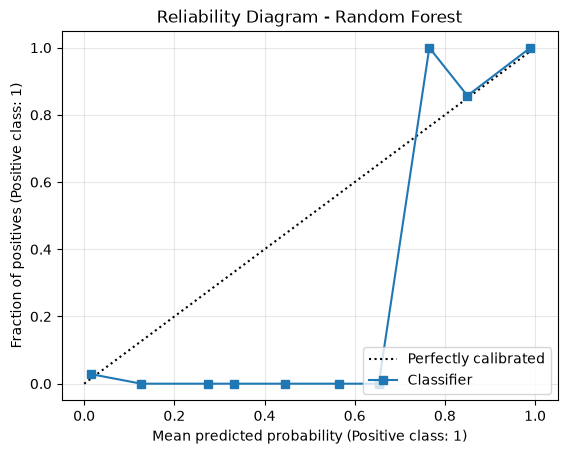

In [80]:
from sklearn.calibration import CalibrationDisplay

last_probabilities = estimator.predict_proba(X_test)

CalibrationDisplay.from_predictions(
    y_test,
    last_probabilities[:, 1],
    n_bins=10,
    strategy="uniform"
)

plt.title("Reliability Diagram - Random Forest")
plt.grid(alpha=0.3)
plt.show()